In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import seaborn as sns

# Importing the ICLR OpenReview Dataset

In [3]:
# Master dataframe made by data/generate.py: every paper (2017-2025) without "Anonymous",
# with its SBERT embedding, last author, and outcome. It lives outside the repo.
iclr2025v2 = pd.read_parquet("data/master.parquet")
iclr2025v2 = iclr2025v2[
    (iclr2025v2["authors"] != "Anonymous") &
    (iclr2025v2["year"] > 2020)
]

iclr2025v2.head()

,paper_idx,year,id,title,abstract,authors,author_ids,decision,scores,keywords,labels,n_authors,last_author,last_author_id,has_author_ids,decision_group,accepted,mean_score,embedding
5637,5637,2021,--GJkm7nt0,Enhancing Visual Representations for Efficient...,"We propose ENVISE, an online distillation fra...","Shashanka Venkataramanan, Bruce W McIntosh, Ab...","~Shashanka_Venkataramanan1, ~Bruce_W_McIntosh1...",Reject,"[4, 5, 5, 4]",[],unlabeled,3,Abhijit Mahalanobis,~Abhijit_Mahalanobis1,True,reject,False,4.500000,"[-0.048169, 0.060541, -0.020332, 0.1288, -0.04..."
5638,5638,2021,--gvHfE3Xf5,Meta-Learning of Structured Task Distributions...,"In recent years, meta-learning, in which a mod...","Sreejan Kumar, Ishita Dasgupta, Jonathan Cohen...","~Sreejan_Kumar1, ~Ishita_Dasgupta1, ~Jonathan_...",Accept (Poster),"[6, 6, 7, 7]","[meta-learning, human cognition, reinforcement...",meta learning,5,Thomas Griffiths,~Thomas_Griffiths1,True,accept,True,6.500000,"[0.053333, -0.003451, -0.059186, -0.092884, -0..."
5639,5639,2021,--rcOeCKRh,CROSS-SUPERVISED OBJECT DETECTION,After learning a new object category from imag...,"Zitian Chen, Zhiqiang Shen, Jiahui Yu, Erik Le...","~Zitian_Chen1, ~Zhiqiang_Shen1, ~Jiahui_Yu1, ~...",Reject,"[6, 4, 6, 6]","[object detection, weakly supervised, transfer...",object detection,4,Erik Learned-Miller,~Erik_Learned-Miller2,True,reject,False,5.500000,"[0.024876, -0.031187, 0.048518, 0.132181, 0.03..."
5640,5640,2021,-2FCwDKRREu,Learning Invariant Representations for Reinfor...,We study how representation learning can accel...,"Amy Zhang, Rowan Thomas McAllister, Roberto Ca...","~Amy_Zhang1, ~Rowan_Thomas_McAllister1, ~Rober...",Accept (Oral),"[7, 7, 9]","[rich observations, bisimulation metrics, repr...",unlabeled,5,Sergey Levine,~Sergey_Levine1,True,accept,True,7.666667,"[-0.102663, 0.114053, -0.030107, 0.016141, -0...."
5641,5641,2021,-5VpoDCExrU,Log representation as an interface for log pro...,"Log files are files that record events, messag...","Mohammad Amin Sadeghi, Shameem Parambath, Ji L...","~Mohammad_Amin_Sadeghi3, spparambath@hbku.edu....",Reject,"[7, 4, 5, 3]","[vector embedding, logs, search, causal analys...",anomaly detection,8,Sanjay Chawla,~Sanjay_Chawla2,True,reject,False,4.750000,"[-0.058153, 0.126793, -0.004362, 0.054084, -0...."


# Paper Representation: Calculating Convex Hull

In [7]:
from pathlib import Path
from openTSNE import TSNE

# Taken from the embeddings.py file
def compute_tsne(
    embeddings: np.ndarray | None = None,
    local_path: Path | str | None = None,
    output_path: Path | str | None = None,
    output_name: str | None = None,
    verbose: bool = True,
    random_state: int = 42,
) -> np.ndarray:
    """
    Fits or loads a 2D t-SNE dimensionality reduction embedding from high-dimensional representations.

    Input:
        embeddings: High-dimensional feature matrix of paper embeddings to project into 2D space.
        local_path: Path to pre-existing .npy file of fitted t-SNE coordinates.
        output_path: Destination directory or file path to store computed t-SNE coordinates.
        output_name: Optional file name if output_path is a directory.
        verbose: Flag controlling whether openTSNE prints fitting progress logs.
        random_state: Integer seed for deterministic t-SNE optimization.

    Output:
        tsne_fit: 2D numpy array containing coordinates of embedded points.
    """
    # Load and return existing t-SNE projection if local file exists
    if local_path is not None:
        file = Path(local_path)
        if file.exists():
            return np.load(file)

    if embeddings is None:
        raise ValueError("Must provide 'embeddings' if 'local_path' does not exist.")

    # Initialize openTSNE and fit coordinates to input embeddings
    tsne = TSNE(n_jobs=-1, verbose=verbose, random_state=random_state)
    tsne_fit = np.asarray(tsne.fit(embeddings))

    # Save fitted coordinates to disk if output destination provided
    if output_path is not None:
        target_file = Path(output_path) / output_name if output_name else Path(output_path)
        target_file.parent.mkdir(parents=True, exist_ok=True)
        np.save(target_file, tsne_fit)

    return tsne_fit

In [8]:
embedding_av = np.stack(iclr2025v2["embedding"])

print("Embedding shape:", embedding_av.shape)

Embedding shape: (36070, 768)


In [9]:
tsne_av = compute_tsne(embeddings=embedding_av)

--------------------------------------------------------------------------------
TSNE(early_exaggeration=12, n_jobs=-1, random_state=42, verbose=True)
--------------------------------------------------------------------------------
===> Finding 90 nearest neighbors using Annoy approximate search using euclidean distance...
   --> Time elapsed: 10.17 seconds
===> Calculating affinity matrix...
   --> Time elapsed: 0.59 seconds
===> Calculating PCA-based initialization...
   --> Time elapsed: 0.19 seconds
===> Running optimization with exaggeration=12.00, lr=3005.83 for 250 iterations...
Iteration   50, KL divergence 6.0747, 50 iterations in 1.6531 sec
Iteration  100, KL divergence 6.1555, 50 iterations in 1.6839 sec
Iteration  150, KL divergence 6.1507, 50 iterations in 1.6577 sec
Iteration  200, KL divergence 6.1509, 50 iterations in 1.6523 sec
Iteration  250, KL divergence 6.1501, 50 iterations in 1.6411 sec
   --> Time elapsed: 8.29 seconds
===> Running optimization with exaggeration

In [10]:
# Making the paper-author dataframe, this just collects the authors and calculates their 
# average paper score and acceptance rate

iclr2025v2 = iclr2025v2.reset_index(drop=True)
records = []

for idx, row in iclr2025v2.iterrows():

    authors = row["authors"]

    if not isinstance(authors, str):
        continue

    paper_authors = list(dict.fromkeys(
        a.strip()
        for a in authors.split(",")
        if a.strip() and a.strip() != "Anonymous"
    ))

    # Mean reviewer score for this paper
    scores = pd.to_numeric(
        pd.Series(row["scores"]),
        errors="coerce"
    )

    mean_score = scores.mean()

    for author in paper_authors:
        records.append({
            "paper_idx": idx,
            "paper_id": row["id"],
            "author": author,
            "decision": row["decision"],
            "score": mean_score,
            "accepted": (
                isinstance(row["decision"], str)
                and row["decision"].startswith("Accept")
            )
        })

author_papers = pd.DataFrame(records)

author_papers.head()

,paper_idx,paper_id,author,decision,score,accepted
0,0,B1-Hhnslg,Jake Snell,Reject,5.000000,False
1,0,B1-Hhnslg,Kevin Swersky,Reject,5.000000,False
2,0,B1-Hhnslg,Richard Zemel,Reject,5.000000,False
3,1,B1-q5Pqxl,Shuohang Wang,Accept (Poster),6.333333,True
4,1,B1-q5Pqxl,Jing Jiang,Accept (Poster),6.333333,True


In [11]:
# This goes through and aligns the convex hull area calculation for each author, 
# adding it to author information
# (assuming that the indices line up correctly to the articles) 

from scipy.spatial import ConvexHull, QhullError

author_hulls = {}
hull_records = []

for author, group in author_papers.groupby("author"):

    paper_indices = group["paper_idx"].to_numpy()

    # Retrieve t-SNE coordinates
    points = tsne_av[paper_indices]

    # Remove duplicate coordinates
    points = np.unique(points, axis=0)

    if len(points) < 3:
        continue

    try:
        hull = ConvexHull(points)

        author_hulls[author] = {
            "hull": hull,
            "points": points
        }

        hull_records.append({
            "author": author,
            "hull_area": hull.volume,
            "hull_perimeter": hull.area,
            "n_hull_vertices": len(hull.vertices)
        })

    except QhullError:
        continue

hull_df = pd.DataFrame(hull_records)

In [12]:
# Author level stats
author_stats = (
    author_papers
    .groupby("author")
    .agg(
        n_papers=("paper_id", "nunique"),
        n_accepted=("accepted", "sum"),
        acceptance_rate=("accepted", "mean"),
        mean_score=("score", "mean")
    )
    .reset_index()
)

author_stats["acceptance_rate"] *= 100

In [17]:
author_results = (
    author_stats
    .merge(hull_df, on="author", how="left")
    .sort_values("n_papers", ascending=False)
    .reset_index(drop=True)
)

author_results.head(20)

,author,n_papers,n_accepted,acceptance_rate,mean_score,hull_area,hull_perimeter,n_hull_vertices
0,Sergey Levine,194,95,48.969072,5.713628,16089.856079,479.622432,11.0
1,Yoshua Bengio,169,82,48.520710,5.656410,17463.864290,489.153002,12.0
2,Yang Liu,164,62,37.804878,5.361523,20141.421217,521.945879,19.0
3,Bo Li,133,41,30.827068,5.231552,17612.946151,497.058894,16.0
4,Pieter Abbeel,122,48,39.344262,5.416120,14605.642593,465.937202,10.0
5,Junchi Yan,121,53,43.801653,5.404054,17138.809436,489.459938,9.0
6,Zhangyang Wang,115,58,50.434783,5.682754,19617.048441,520.287852,14.0
7,Tongliang Liu,113,44,38.938053,5.279646,15553.021129,474.401774,12.0
8,Bo Han,111,38,34.234234,5.203604,15736.143842,472.995947,13.0
9,Dacheng Tao,106,34,32.075472,5.189780,19200.920517,507.068228,13.0


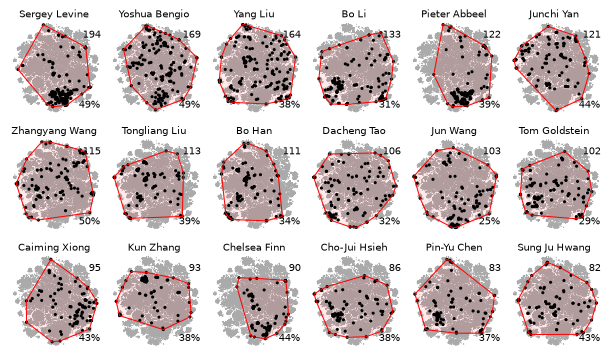

In [18]:
# Rank authors by number of papers
top_authors = (
    author_stats
    .sort_values("n_papers", ascending=False)
    ["author"]
    .head(18)
    .tolist()
)

# Background: all papers
fig_plot, axs = plt.subplots(
    nrows=3,
    ncols=6,
    figsize=(6.0, 3.5),
    layout="constrained"
)

for num, author in enumerate(top_authors):

    ax = axs.flat[num]

    # Retrieve this author's papers
    group = author_papers[
        author_papers["author"] == author
    ]

    paper_indices = group["paper_idx"].to_numpy()

    # Retrieve corresponding t-SNE coordinates
    points = tsne_av[paper_indices]

    # Background: all papers
    ax.scatter(
        *tsne_av.T,
        s=.5,
        ec="none",
        c="#aaaaaa",
        rasterized=True
    )

    # Highlight author's papers
    ax.scatter(
        *points.T,
        s=5,
        ec="none",
        c="k",
        zorder=2
    )

    # Retrieve author-level statistics
    stats = author_stats.loc[
        author_stats["author"] == author
    ].iloc[0]

    n_papers = stats["n_papers"]
    acceptance_rate = stats["acceptance_rate"]

    # Retrieve previously calculated convex hull
    if author in author_hulls:

        hull = author_hulls[author]["hull"]
        hull_points = author_hulls[author]["points"][hull.vertices]

        # Close polygon
        hull_points = np.vstack([
            hull_points,
            hull_points[0]
        ])

        # Draw hull boundary
        ax.plot(
            hull_points[:, 0],
            hull_points[:, 1],
            color="red",
            linewidth=.7,
            zorder=3
        )

        # Fill hull
        ax.fill(
            hull_points[:, 0],
            hull_points[:, 1],
            color="red",
            alpha=.08,
            zorder=1
        )

    ax.axis("equal")
    ax.axis("off")

    # Author name
    ax.set_title(
        author,
        fontsize=7,
        y=.92,
        x=.48
    )

    # Number of papers
    ax.text(
        .99, .8,
        f"{n_papers}",
        ha="right",
        transform=ax.transAxes,
        fontsize=7
    )

    # Acceptance rate
    ax.text(
        .99, .1,
        f"{acceptance_rate:.0f}%",
        fontsize=7,
        ha="right",
        transform=ax.transAxes
    )

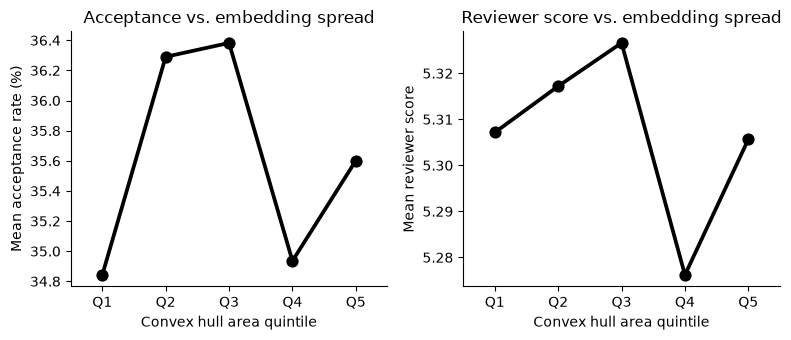

In [ ]:
plot_df = author_results.dropna(
    subset=["hull_area", "acceptance_rate", "mean_score"]
).copy()

# Exclude authors with very few papers
plot_df = plot_df[plot_df["n_papers"] >= 3].copy()

# Divide into hull-area quintiles
plot_df["hull_bin"] = pd.qcut(
    plot_df["hull_area"],
    q=5,
    labels=["Q1", "Q2", "Q3", "Q4", "Q5"]
)

binned = plot_df.groupby("hull_bin", observed=True).agg(
    mean_acceptance=("acceptance_rate", "mean"),
    mean_score=("mean_score", "mean"),
    n_authors=("author", "count"),
    mean_hull_area=("hull_area", "mean")
).reset_index()

fig, axs = plt.subplots(1, 2, figsize=(8, 3.5))

sns.pointplot(
    data=binned,
    x="hull_bin",
    y="mean_acceptance",
    ax=axs[0],
    color="black"
)

sns.pointplot(
    data=binned,
    x="hull_bin",
    y="mean_score",
    ax=axs[1],
    color="black"
)

axs[0].set(
    xlabel="Convex hull area quintile",
    ylabel="Mean acceptance rate (%)",
    title="Acceptance vs. embedding spread"
)

axs[1].set(
    xlabel="Convex hull area quintile",
    ylabel="Mean reviewer score",
    title="Reviewer score vs. embedding spread"
)

sns.despine()
plt.tight_layout()
plt.show()

In [ ]:
# Merge hull statistics with author publication counts
hull_summary = (
    hull_df
    .merge(
        author_stats[["author", "n_papers"]],
        on="author",
        how="left"
    )
    .dropna(subset=["hull_area", "hull_perimeter"])
    .copy()
)

# Additional geometric statistics
hull_summary["log_hull_area"] = np.log1p(
    hull_summary["hull_area"]
)

hull_summary["area_per_paper"] = (
    hull_summary["hull_area"] / hull_summary["n_papers"]
)

hull_summary["perimeter_area_ratio"] = (
    hull_summary["hull_perimeter"] /
    np.sqrt(hull_summary["hull_area"])
)

print("Number of authors:", len(hull_summary))
print("\nSummary statistics:")
print(
    hull_summary[
        [
            "n_papers",
            "hull_area",
            "hull_perimeter",
            "n_hull_vertices",
            "area_per_paper"
        ]
    ].describe(percentiles=[.25, .5, .75, .9, .95])
)

Number of authors: 15867

Summary statistics:
           n_papers     hull_area  hull_perimeter  n_hull_vertices  \
count  15867.000000  1.586700e+04    15867.000000     15867.000000   
mean       6.882397  2.486691e+03      211.966408         4.248188   
std        7.832566  3.274307e+03      113.269781         1.561759   
min        3.000000  4.340148e-08        0.056083         3.000000   
25%        3.000000  1.692236e+02      123.951831         3.000000   
50%        4.000000  1.127645e+03      212.646181         4.000000   
75%        7.000000  3.547861e+03      294.523158         5.000000   
90%       13.000000  7.084412e+03      363.512636         6.000000   
95%       19.000000  9.869195e+03      402.031464         7.000000   
max      194.000000  2.014142e+04      521.945879        19.000000   

       area_per_paper  
count    1.586700e+04  
mean     3.208305e+02  
std      3.398316e+02  
min      1.446716e-08  
25%      4.349904e+01  
50%      2.218843e+02  
75%      4.8624

In [ ]:
# Metrics and their display labels / units
metrics = {
    "n_papers": ("Papers per author", "papers"),
    "hull_area": ("Convex hull area", "t-SNE units²"),
    "hull_perimeter": ("Convex hull perimeter", "t-SNE units"),
    "n_hull_vertices": ("Hull vertices", "vertices"),
    "area_per_paper": ("Hull area per paper", "t-SNE units² / paper")
}

rows = []

for col, (label, unit) in metrics.items():
    s = hull_summary[col].dropna()

    rows.append({
        "Measure": label,
        "Unit": unit,
        "Authors (N)": len(s),
        "Mean": s.mean(),
        "SD": s.std(),
        "Median": s.median(),
        "25th percentile": s.quantile(.25),
        "75th percentile": s.quantile(.75),
        "Minimum": s.min(),
        "Maximum": s.max()
    })

summary_table = pd.DataFrame(rows)

# Format numerical columns
numeric_cols = [
    "Mean", "SD", "Median",
    "25th percentile", "75th percentile",
    "Minimum", "Maximum"
]

for col in numeric_cols:
    summary_table[col] = summary_table[col].map(
        lambda x: f"{x:,.2f}" if pd.notna(x) else "—"
    )

summary_table["Authors (N)"] = (
    summary_table["Authors (N)"].map("{:,}".format)
)

# Rename columns for clarity
summary_display = summary_table.rename(columns={
    "Authors (N)": "N Authors",
    "25th percentile": "25th percentile",
    "75th percentile": "75th percentile"
})

# Display simple table
display(
    summary_display.reset_index(drop=True)
)


,Measure,Unit,N Authors,Mean,SD,Median,25th percentile,75th percentile,Minimum,Maximum
0,Papers per author,papers,"15,867",6.88,7.83,4.00,3.00,7.00,3.00,194.00
1,Convex hull area,t-SNE units²,"15,867","2,486.69","3,274.31","1,127.65",169.22,"3,547.86",0.00,"20,141.42"
2,Convex hull perimeter,t-SNE units,"15,867",211.97,113.27,212.65,123.95,294.52,0.06,521.95
3,Hull vertices,vertices,"15,867",4.25,1.56,4.00,3.00,5.00,3.00,19.00
4,Hull area per paper,t-SNE units² / paper,"15,867",320.83,339.83,221.88,43.50,486.25,0.00,"2,758.44"
